# Customer Retention Intelligence
### End-to-end churn prediction, customer risk segmentation & retention campaign prioritization

**Portfolio project | Data Science / Machine Learning | Python · Pandas · SQL-ready analytics · scikit-learn**

> **Business question:** Which customers are most likely to leave, what factors are associated with churn, and how should a retention team prioritize contacts when its campaign budget is limited?

| Project component | What is delivered |
|---|---|
| Exploratory analytics | Data quality checks, churn rate, customer segments, risk lift and confidence intervals |
| Predictive modelling | A from-scratch categorical Naive Bayes benchmark, Logistic Regression and Random Forest |
| Model evaluation | Train / validation / test split, PR-AUC, ROC-AUC, threshold tuning, confusion matrix and calibration |
| Explainability | Permutation importance and segment-level interpretation |
| Business decision | Expected-value prioritization, budget-constrained contact list and sensitivity analysis |
| Reproducibility | Fixed random seed, preprocessing pipelines, documented assumptions and exportable artifacts |

**Important scope note.** This is a portfolio-grade classification and decision-support case study using a public sample dataset. It is not a production churn system, causal retention experiment, or a trained Next Best Offer model. The dataset does not contain campaign exposure, offer response or randomized treatment outcomes.

## 1. Business framing & success criteria

A telecom retention team has limited time and budget. Contacting every customer is expensive, while contacting only customers predicted to churn may generate many false positives. The analytical workflow therefore needs to answer four questions:

1. **Risk:** How well can customer churn be ranked using the available account and service attributes?
2. **Drivers:** Which observed features are most associated with churn in this sample?
3. **Operating point:** What classification threshold gives a useful precision–recall trade-off?
4. **Action:** Given explicit campaign assumptions and a fixed budget, which customers should be prioritized?

### Success criteria

- Beat a simple majority/prior baseline on **Average Precision (PR-AUC)**.
- Report recall and precision together; accuracy alone is not sufficient for an imbalanced target.
- Keep the test set untouched until the final evaluation.
- Fit imputers, encoders, scaling and numeric bin boundaries on training data only.
- Separate model-based estimates from business assumptions and causal claims.

### Prediction target and operational caveat

The public dataset labels whether a customer left (`Churn`). It does not provide dated snapshots or a true future observation window. This project therefore evaluates **churn classification on a cross-sectional sample**, not a validated forecast of churn over the next 30/60/90 days. A production model would require an explicit observation date, prediction horizon and time-based validation.

## 2. Dataset & provenance

The project uses the **IBM Telco Customer Churn** sample dataset distributed through Kaggle. The Kaggle dataset card describes 7,043 customer records and 21 columns, including the target `Churn`, customer demographics, subscribed services and account information.

- Dataset page: <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>
- Public IBM mirror (used for automatic download when no local CSV is found): <https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv>

Each row represents one customer. `customerID` is an identifier and is **excluded from model features**. `TotalCharges` is stored as text in the source and is parsed as numeric; blank values are retained as missing and imputed inside the training pipeline.

### Main feature groups

| Group | Example columns |
|---|---|
| Customer profile | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Relationship | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Services | `PhoneService`, `InternetService`, `OnlineSecurity`, `TechSupport`, streaming add-ons |
| Charges | `MonthlyCharges`, `TotalCharges` |
| Target | `Churn` (`Yes` / `No`) |

**Data limitations:** this is a historical, anonymized sample from a fictional telecom context. It is relatively small for a “big data” claim, has no event-level behaviour or campaign history, and should not be treated as representative of a current telecom operator without external validation.

## 3. Reproducibility & imports

Install dependencies with `pip install -r requirements.txt`. The data loader checks the `CHURN_DATA_PATH` environment variable, then `data/`, then the working directory, and finally downloads the public IBM mirror of the dataset. If you are offline, place the CSV in `data/`.

In [1]:
from __future__ import annotations

import os
import json
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

print(f"pandas: {pd.__version__}")
import sklearn
print(f"scikit-learn: {sklearn.__version__}")

pandas: 2.3.2
scikit-learn: 1.7.1


## 4. Load the raw data

The loader checks an environment variable, a `data/` directory and the working directory before falling back to the public mirror. The source is never silently replaced with synthetic data, and the loaded source is printed so every run is traceable.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

LOCAL_CANDIDATES = [
    os.environ.get("CHURN_DATA_PATH"),
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "Telco-Customer-Churn.csv",
]


def load_dataset() -> tuple[pd.DataFrame, str]:
    """Load the Telco churn CSV from a local path or the public IBM mirror."""
    for candidate in LOCAL_CANDIDATES:
        if candidate and Path(candidate).expanduser().is_file():
            path = Path(candidate).expanduser()
            return pd.read_csv(path), str(path.resolve())

    try:
        data = pd.read_csv(DATA_URL)
        return data, DATA_URL
    except Exception as mirror_error:
        # Optional fallback for environments where KaggleHub is already configured.
        try:
            import kagglehub
            downloaded_dir = Path(kagglehub.dataset_download("blastchar/telco-customer-churn"))
            csv_files = sorted(downloaded_dir.rglob("*.csv"))
            if not csv_files:
                raise FileNotFoundError(f"No CSV file found under {downloaded_dir}")
            return pd.read_csv(csv_files[0]), str(csv_files[0])
        except Exception as kaggle_error:
            raise RuntimeError(
                "Could not load the Telco churn dataset. Put the CSV in ./data/ "
                "or ./Dataset.csv, or set CHURN_DATA_PATH. Automatic download "
                f"from the IBM mirror failed: {mirror_error}. KaggleHub fallback failed: {kaggle_error}"
            ) from kaggle_error


df_raw, DATA_SOURCE = load_dataset()
print(f"Loaded from: {DATA_SOURCE}")
print(f"Raw shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded from: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Raw shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


## 5. Data quality & target preparation

Before modelling, validate the schema, standardize column names, parse `TotalCharges`, inspect duplicate customer IDs and map the target to 0/1. No imputation is performed here: missing-value treatment belongs inside the modelling pipeline so that statistics are learned from the training partition only.

In [3]:
EXPECTED_COLUMNS = {
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents",
    "tenure", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
}

missing_columns = EXPECTED_COLUMNS - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Dataset schema mismatch. Missing columns: {sorted(missing_columns)}")

df = df_raw.copy()
df.columns = df.columns.str.strip()

# Parse numeric charges; the source contains blank strings in TotalCharges.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip().replace("", pd.NA),
    errors="coerce",
)

# Standardize the binary target and report any unexpected values.
target_map = {"Yes": 1, "No": 0}
df["Churn"] = df["Churn"].astype("string").str.strip().map(target_map)
invalid_target_rows = int(df["Churn"].isna().sum())
if invalid_target_rows:
    warnings.warn(f"Dropping {invalid_target_rows} rows with an unmapped target.")
    df = df.dropna(subset=["Churn"]).copy()
df["Churn"] = df["Churn"].astype("int8")

# Customer IDs are expected to be unique. Keep the first record only if duplicates exist.
duplicate_ids = int(df["customerID"].duplicated().sum())
if duplicate_ids:
    warnings.warn(f"Found {duplicate_ids} duplicate customer IDs; keeping the first record.")
    df = df.drop_duplicates(subset="customerID", keep="first").copy()

quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(quality_summary)

print(f"Duplicate customer IDs found: {duplicate_ids}")
print(f"Rows removed for invalid target: {invalid_target_rows}")
print(f"Clean modelling frame: {df.shape[0]:,} rows × {df.shape[1]} columns")

,dtype,missing_count,missing_pct,unique_values
customerID,object,0,0.000,7043
gender,object,0,0.000,2
SeniorCitizen,int64,0,0.000,2
Partner,object,0,0.000,2
Dependents,object,0,0.000,2
tenure,int64,0,0.000,73
PhoneService,object,0,0.000,2
MultipleLines,object,0,0.000,3
InternetService,object,0,0.000,3
OnlineSecurity,object,0,0.000,3


Duplicate customer IDs found: 0
Rows removed for invalid target: 0
Clean modelling frame: 7,043 rows × 21 columns


### Data-quality decisions

- **`customerID`:** kept for traceability and output files, but never passed to the model.
- **`TotalCharges`:** blanks become `NaN`; median imputation is fitted separately on training data. This is conservative and avoids assuming that every blank necessarily means zero spend.
- **Categorical missing values:** most-frequent imputation is learned from training data.
- **Duplicates / invalid labels:** counted and explicitly reported before any removal.
- **No global quantile binning:** numerical transformations are fitted only after the train/validation/test split.

## 6. Exploratory data analysis (EDA)

The first pass establishes the target prevalence and checks whether churn is concentrated in specific customer segments. Segment differences are **descriptive associations**, not causal effects.

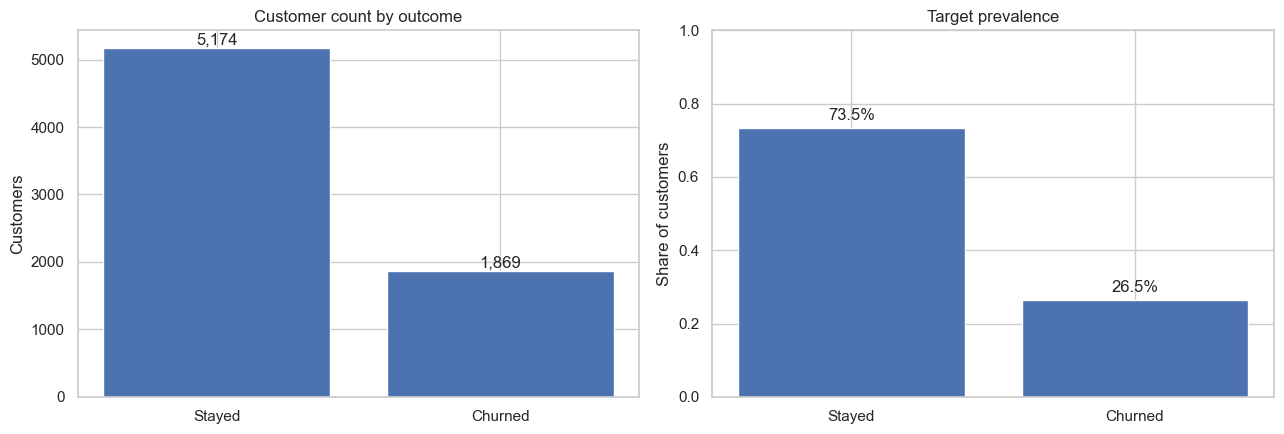

Overall churn rate: 26.54%


In [4]:
churn_rate = df["Churn"].mean()
target_counts = df["Churn"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels = ["Stayed", "Churned"]
axes[0].bar(labels, [target_counts.get(0, 0), target_counts.get(1, 0)])
axes[0].set_title("Customer count by outcome")
axes[0].set_ylabel("Customers")
for i, value in enumerate([target_counts.get(0, 0), target_counts.get(1, 0)]):
    axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")

axes[1].bar(labels, [1 - churn_rate, churn_rate])
axes[1].set_title("Target prevalence")
axes[1].set_ylabel("Share of customers")
axes[1].set_ylim(0, 1)
for i, value in enumerate([1 - churn_rate, churn_rate]):
    axes[1].text(i, value + 0.02, f"{value:.1%}", ha="center")
plt.tight_layout()
plt.show()

print(f"Overall churn rate: {churn_rate:.2%}")

### Churn rates with confidence intervals

To avoid over-interpreting tiny groups, show both sample size and a 95% Wilson confidence interval for each category. The interval reflects sampling uncertainty under a simple binomial view; it does not correct for selection bias or multiple comparisons.

In [5]:
def wilson_interval(successes: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    margin = z * np.sqrt((p * (1 - p) / n) + (z**2 / (4 * n**2))) / denominator
    return center - margin, center + margin


def churn_segment_table(data: pd.DataFrame, column: str, min_n: int = 1) -> pd.DataFrame:
    rows = []
    for segment, group in data.groupby(column, dropna=False, observed=False):
        n = len(group)
        if n < min_n:
            continue
        churned = int(group["Churn"].sum())
        low, high = wilson_interval(churned, n)
        rate = churned / n if n else np.nan
        rows.append({
            "feature": column,
            "segment": str(segment),
            "customers": n,
            "churned": churned,
            "churn_rate": rate,
            "rate_ci_low": low,
            "rate_ci_high": high,
            "lift_vs_average": rate / churn_rate if churn_rate else np.nan,
        })
    return pd.DataFrame(rows).sort_values("churn_rate", ascending=False)


eda_features = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]
eda_tables = [churn_segment_table(df, feature) for feature in eda_features]
segment_summary = pd.concat(eda_tables, ignore_index=True)
display(segment_summary.sort_values(["feature", "churn_rate"], ascending=[True, False]))

,feature,segment,customers,churned,churn_rate,rate_ci_low,rate_ci_high,lift_vs_average
0,Contract,Month-to-month,3875,1655,0.427,0.412,0.443,1.609
1,Contract,One year,1473,166,0.113,0.098,0.130,0.425
2,Contract,Two year,1695,48,0.028,0.021,0.037,0.107
3,InternetService,Fiber optic,3096,1297,0.419,0.402,0.436,1.579
4,InternetService,DSL,2421,459,0.190,0.174,0.206,0.714
5,InternetService,No,1526,113,0.074,0.062,0.088,0.279
13,OnlineSecurity,No,3498,1461,0.418,0.401,0.434,1.574
14,OnlineSecurity,Yes,2019,295,0.146,0.131,0.162,0.551
15,OnlineSecurity,No internet service,1526,113,0.074,0.062,0.088,0.279
6,PaymentMethod,Electronic check,2365,1071,0.453,0.433,0.473,1.707


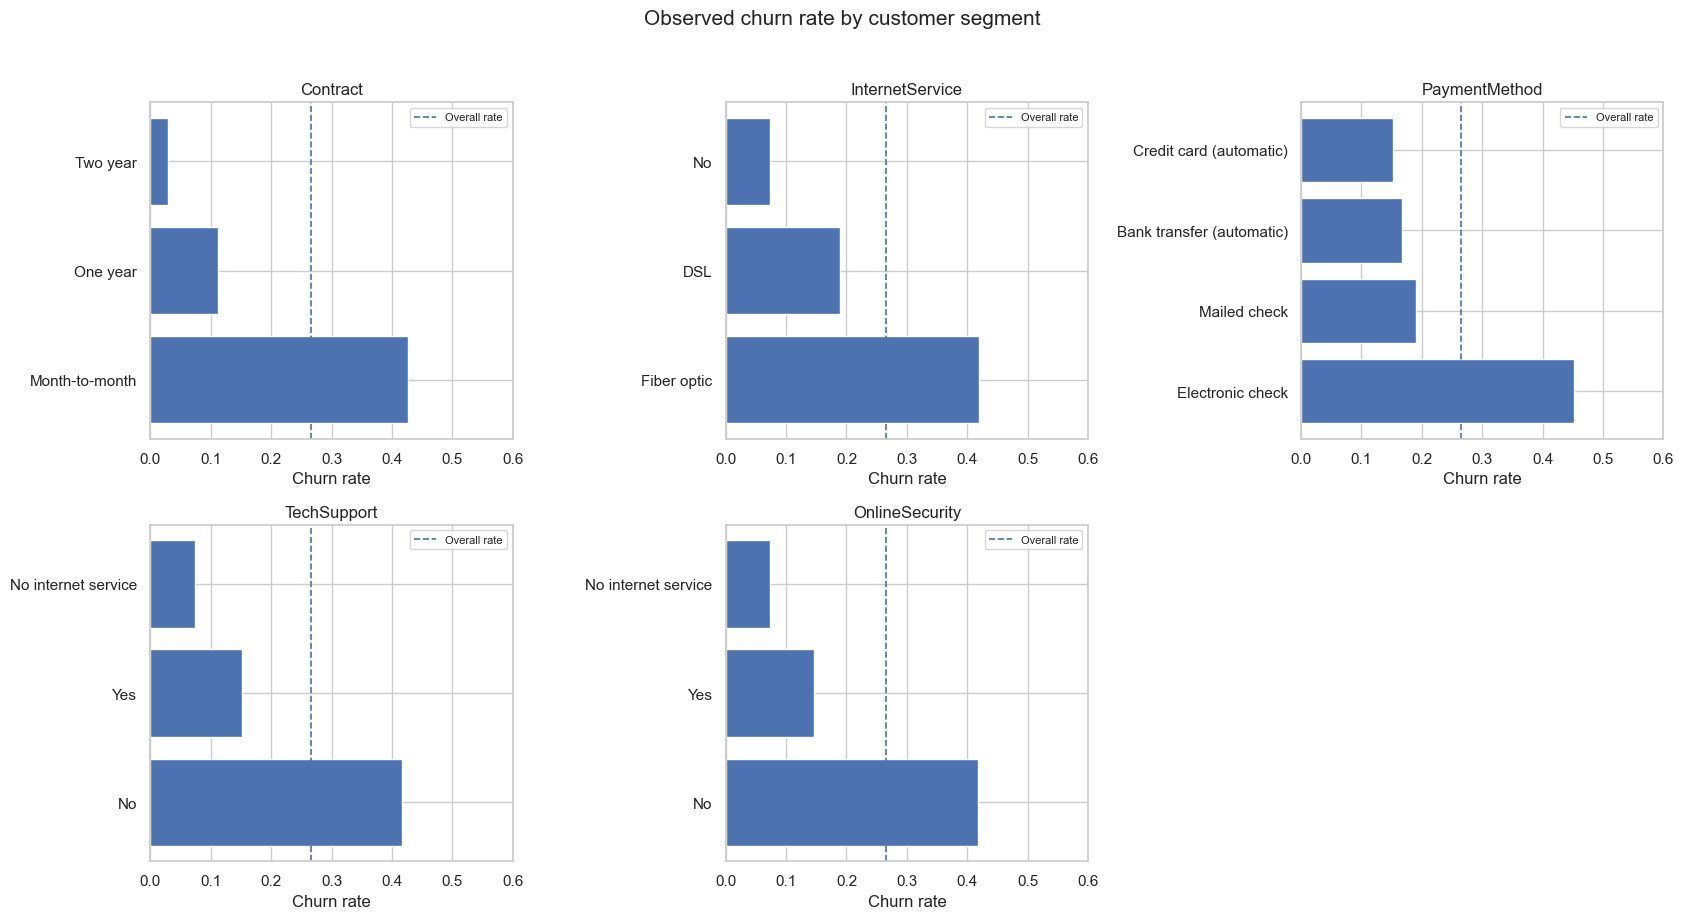

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feature in zip(axes.flat, eda_features):
    plot_data = churn_segment_table(df, feature)
    ax.barh(plot_data["segment"], plot_data["churn_rate"])
    ax.axvline(churn_rate, linestyle="--", linewidth=1.2, label="Overall rate")
    ax.set_title(feature)
    ax.set_xlabel("Churn rate")
    ax.set_xlim(0, min(1, max(0.6, plot_data["churn_rate"].max() * 1.15)))
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Observed churn rate by customer segment", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### Customer lifecycle & charges

Tenure is a key lifecycle variable. The following cohorts are used for interpretation only; they are not precomputed across the full dataset and injected into the model.

,feature,segment,customers,churned,churn_rate,rate_ci_low,rate_ci_high,lift_vs_average
0,tenure_cohort,0–6 months,1481,784,0.529,0.504,0.555,1.995
1,tenure_cohort,7–12 months,705,253,0.359,0.324,0.395,1.352
2,tenure_cohort,13–24 months,1024,294,0.287,0.260,0.316,1.082
3,tenure_cohort,25–48 months,1594,325,0.204,0.185,0.224,0.768
4,tenure_cohort,49–72 months,2239,213,0.095,0.084,0.108,0.358


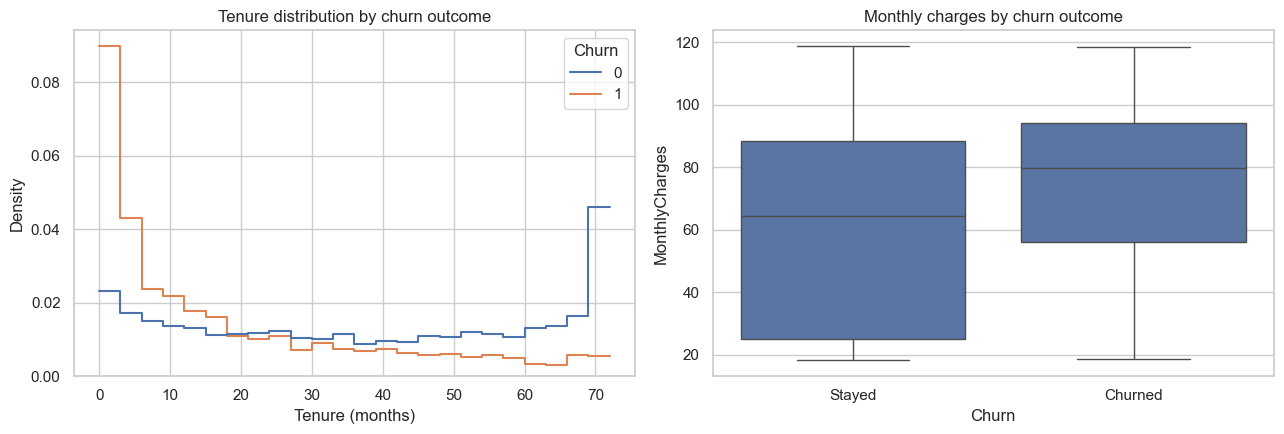

In [7]:
eda_df = df.copy()
tenure_bins = [-1, 6, 12, 24, 48, 72]
tenure_labels = ["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
eda_df["tenure_cohort"] = pd.cut(eda_df["tenure"], bins=tenure_bins, labels=tenure_labels)
cohort_rates = churn_segment_table(eda_df, "tenure_cohort")
display(cohort_rates)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, stat="density", common_norm=False,
             element="step", fill=False, ax=axes[0])
axes[0].set_title("Tenure distribution by churn outcome")
axes[0].set_xlabel("Tenure (months)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_xticks([0, 1], ["Stayed", "Churned"])
axes[1].set_title("Monthly charges by churn outcome")
plt.tight_layout()
plt.show()

### EDA takeaways (data-driven, not causal)

- **Contract is the strongest categorical signal.** Month-to-month customers churn at 42.7% (1,655 of 3,875), against 11.3% on one-year and 2.8% on two-year contracts. The confidence intervals for these groups do not overlap.
- **The first months are the riskiest.** Customers in their first six months churn at 52.9%, falling to 9.5% after four years. Tenure is also the most important feature in the model (section 15).
- **Fibre-optic internet and electronic-cheque payment go with higher churn.** Fibre customers churn at 41.9%, against 19.0% on DSL and 7.4% without internet service. Electronic-cheque customers churn at 45.3%. These are associations: fibre may be correlated with price or service quality, and this dataset cannot separate those effects.
- **Support and security add-ons go with lower churn.** Customers without tech support churn at 41.6%, against 15.2% of those with it. The pattern is almost identical for online security (41.8% versus 14.6%).

Use rate, segment size and uncertainty together. Avoid statements such as “fibre causes churn” or “a discount will prevent churn”: this dataset is observational and contains no randomised intervention.

## 7. SQL analytics layer

The same cleaned frame is loaded into an in-memory SQLite table to demonstrate SQL-based aggregation before modelling. These queries are deliberately simple and portable; SQLite on 7k rows is **not** evidence of big-data performance. In an operator environment, run equivalent queries against the analytical warehouse (for example, PostgreSQL / ClickHouse / Snowflake) and materialize point-in-time feature tables.

In [8]:
import sqlite3

contract_sql = """
SELECT
    Contract,
    COUNT(*) AS customer_count,
    SUM(Churn) AS churned_customers,
    ROUND(1.0 * SUM(Churn) / COUNT(*), 4) AS churn_rate,
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges
FROM customers
GROUP BY Contract
ORDER BY churn_rate DESC;
"""

tenure_sql = """
WITH customer_lifecycle AS (
    SELECT
        customerID,
        Churn,
        CASE
            WHEN tenure <= 6 THEN '0-6 months'
            WHEN tenure <= 12 THEN '7-12 months'
            WHEN tenure <= 24 THEN '13-24 months'
            WHEN tenure <= 48 THEN '25-48 months'
            ELSE '49-72 months'
        END AS tenure_cohort
    FROM customers
)
SELECT
    tenure_cohort,
    COUNT(*) AS customer_count,
    SUM(Churn) AS churned_customers,
    ROUND(1.0 * SUM(Churn) / COUNT(*), 4) AS churn_rate
FROM customer_lifecycle
GROUP BY tenure_cohort
ORDER BY MIN(CASE tenure_cohort
    WHEN '0-6 months' THEN 1 WHEN '7-12 months' THEN 2
    WHEN '13-24 months' THEN 3 WHEN '25-48 months' THEN 4 ELSE 5 END);
"""

with sqlite3.connect(":memory:") as connection:
    df.to_sql("customers", connection, index=False, if_exists="replace")
    sql_contract_summary = pd.read_sql_query(contract_sql, connection)
    sql_tenure_summary = pd.read_sql_query(tenure_sql, connection)

print("Churn by contract (SQL):")
display(sql_contract_summary)
print("Churn by lifecycle cohort (SQL + CTE):")
display(sql_tenure_summary)

Churn by contract (SQL):


,Contract,customer_count,churned_customers,churn_rate,avg_monthly_charges
0,Month-to-month,3875,1655,0.427,66.400
1,One year,1473,166,0.113,65.050
2,Two year,1695,48,0.028,60.770


Churn by lifecycle cohort (SQL + CTE):


,tenure_cohort,customer_count,churned_customers,churn_rate
0,0-6 months,1481,784,0.529
1,7-12 months,705,253,0.359
2,13-24 months,1024,294,0.287
3,25-48 months,1594,325,0.204
4,49-72 months,2239,213,0.095


## 8. Train / validation / test design

A stratified three-way split keeps the target distribution reasonably stable:

- **70% train:** fit preprocessing and models.
- **15% validation:** compare candidate models and select a classification threshold.
- **15% test:** one final, untouched performance estimate.

The validation set must not be used as the final headline score. The test set is only evaluated after model selection and threshold tuning are complete.

In [9]:
from sklearn.model_selection import train_test_split

TARGET = "Churn"
IDENTIFIER = "customerID"

X = df.drop(columns=[TARGET, IDENTIFIER]).copy()
y = df[TARGET].copy()
customer_ids = df[IDENTIFIER].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "churn_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

,split,rows,churn_rate
0,train,4930,0.265
1,validation,1056,0.265
2,test,1057,0.266


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 9. Preprocessing pipeline

All learned preprocessing is encapsulated in a scikit-learn `Pipeline` / `ColumnTransformer`:

- numeric: median imputation (with missingness indicators) → standardization;
- categorical: most-frequent imputation → one-hot encoding with unknown-category tolerance.

This prevents leakage from validation/test rows and makes the final estimator reusable for future scoring.

In [10]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
], remainder="drop")

## 10. Categorical Naive Bayes from scratch

The project includes a categorical Naive Bayes classifier implemented with NumPy and pandas only. It is a transparent probabilistic baseline and is benchmarked alongside the scikit-learn pipelines.

Two design choices matter:

1. Numeric variables are discretised into quantile bins. The bin edges are learned from the training data only.
2. Laplace smoothing reserves an explicit *unseen* code for categories that never appear in training, so no class probability collapses to zero.

The class follows the scikit-learn estimator conventions (`fit`, `predict_proba`, `predict`, `get_params`), so it can be cloned and calibrated like the other models.

In [11]:
class ScratchCategoricalNB(BaseEstimator, ClassifierMixin):
    """Categorical Naive Bayes with quantile-binned numeric features.

    Numeric columns are discretised into quantile bins learned in ``fit``.
    NaN values get their own bin. Categorical columns are mapped to integer
    codes using the training vocabulary; unseen categories share one code.
    Counts are smoothed with Laplace (additive) smoothing ``alpha``.
    """

    _MISSING = "__missing__"

    def __init__(self, alpha: float = 1.0, n_bins: int = 5):
        self.alpha = alpha
        self.n_bins = n_bins

    def _encode(self, column: str, values) -> np.ndarray:
        if self.is_numeric_[column]:
            numeric = pd.to_numeric(pd.Series(values), errors="coerce").to_numpy(dtype=float)
            edges = self.edges_[column]
            codes = np.digitize(numeric, edges)
            codes = np.where(np.isnan(numeric), len(edges) + 1, codes)
            return codes.astype(int)
        text = pd.Series(values).astype("object").fillna(self._MISSING).astype(str)
        vocabulary = self.vocab_[column]
        return text.map(vocabulary).fillna(len(vocabulary)).astype(int).to_numpy()

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.is_numeric_ = {c: pd.api.types.is_numeric_dtype(X[c]) for c in X.columns}
        self.edges_, self.vocab_, self.log_likelihood_ = {}, {}, {}
        self.class_log_prior_ = np.log(np.array([(y == c).mean() for c in self.classes_]))

        for column in X.columns:
            values = X[column]
            if self.is_numeric_[column]:
                numeric = values.to_numpy(dtype=float)
                observed = numeric[~np.isnan(numeric)]
                quantiles = np.linspace(0, 1, self.n_bins + 1)[1:-1]
                self.edges_[column] = np.unique(np.quantile(observed, quantiles)) if observed.size else np.array([])
                n_codes = len(self.edges_[column]) + 2          # bins + missing
            else:
                text = values.astype("object").fillna(self._MISSING).astype(str)
                uniques = pd.unique(text)
                self.vocab_[column] = {value: i for i, value in enumerate(uniques)}
                n_codes = len(uniques) + 1                      # known categories + unseen

            codes = self._encode(column, values)
            counts = np.stack([np.bincount(codes[y == c], minlength=n_codes) for c in self.classes_])
            totals = counts.sum(axis=1, keepdims=True)
            self.log_likelihood_[column] = np.log((counts + self.alpha) / (totals + self.alpha * n_codes))
        return self

    def predict_proba(self, X) -> np.ndarray:
        X = pd.DataFrame(X).reset_index(drop=True)
        log_posterior = np.tile(self.class_log_prior_, (len(X), 1))
        for column in self.feature_names_in_:
            codes = self._encode(column, X[column])
            log_posterior += self.log_likelihood_[column][:, codes].T
        log_posterior -= log_posterior.max(axis=1, keepdims=True)
        probabilities = np.exp(log_posterior)
        return probabilities / probabilities.sum(axis=1, keepdims=True)

    def predict(self, X) -> np.ndarray:
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


scratch_nb = ScratchCategoricalNB(alpha=1.0, n_bins=5)
scratch_nb.fit(X_train, y_train)
nb_val_prob = scratch_nb.predict_proba(X_val)[:, list(scratch_nb.classes_).index(1)]
print("Scratch Naive Bayes fitted.")

Scratch Naive Bayes fitted.


## 11. Train and compare candidate models

The benchmark includes:

- **Prior baseline:** predicts the training churn prevalence for every customer.
- **Scratch Categorical Naive Bayes:** transparent probabilistic baseline.
- **Logistic Regression:** interpretable linear model with regularization.
- **Random Forest:** non-linear ensemble that can capture interactions.

Average Precision (PR-AUC) is the primary selection metric because the positive class is the minority. ROC-AUC is reported as a complementary ranking metric.

In [12]:
models = {
    "Prior baseline": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DummyClassifier(strategy="prior")),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=4,
            max_features="sqrt",
            n_jobs=1,
            random_state=RANDOM_STATE,
        )),
    ]),
}


def evaluate_probabilities(y_true, probabilities, threshold: float = 0.5) -> dict:
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)
    return {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Precision@0.5": precision_score(y_true, predictions, zero_division=0),
        "Recall@0.5": recall_score(y_true, predictions, zero_division=0),
        "F1@0.5": f1_score(y_true, predictions, zero_division=0),
        "Brier": brier_score_loss(y_true, probabilities),
    }


validation_probabilities = {"Scratch Naive Bayes": nb_val_prob}
for model_name, estimator in models.items():
    estimator.fit(X_train, y_train)
    validation_probabilities[model_name] = estimator.predict_proba(X_val)[:, 1]

validation_results = pd.DataFrame({
    name: evaluate_probabilities(y_val, probs)
    for name, probs in validation_probabilities.items()
}).T.sort_values("PR-AUC", ascending=False)

display(validation_results.style.format("{:.3f}"))

,PR-AUC,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5,Brier
Logistic Regression,0.631,0.846,0.650,0.596,0.622,0.137
Random Forest,0.619,0.837,0.620,0.507,0.558,0.139
Scratch Naive Bayes,0.607,0.818,0.477,0.825,0.605,0.236
Prior baseline,0.265,0.500,0.000,0.000,0.000,0.195


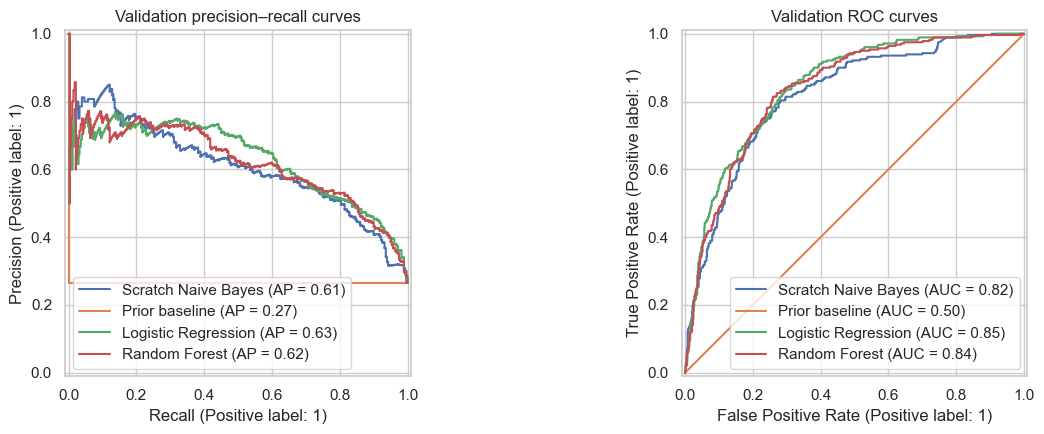

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, probabilities in validation_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_val, probabilities, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_val, probabilities, name=name, ax=axes[1])
axes[0].set_title("Validation precision–recall curves")
axes[1].set_title("Validation ROC curves")
plt.tight_layout()
plt.show()

## 12. Model selection & threshold tuning

The candidate with the highest validation PR-AUC is selected. The selected estimator is then sigmoid-calibrated with five folds **inside the training partition only**. Calibrated probabilities on validation data are used to tune the F1 threshold. This keeps the probability scale more appropriate for expected-value analysis; calibration quality is still checked on the untouched test set. The chosen threshold is a decision choice, not a universal constant; the final business section uses an explicit expected-value rule instead.

Selected model by validation PR-AUC: Logistic Regression
Validation F1-optimal threshold: 0.290
Validation F1 at selected threshold: 0.628


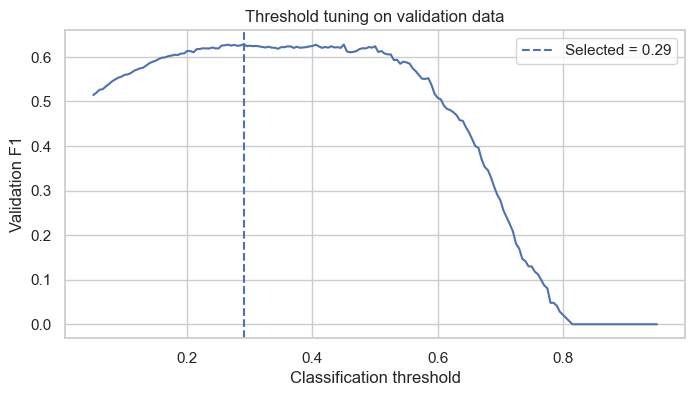

In [14]:
best_model_name = validation_results.index[0]
model_registry = {**models, "Scratch Naive Bayes": scratch_nb}
base_model = model_registry[best_model_name]

# Calibrate the selected estimator using training folds only. Validation is used
# afterwards to tune the operating threshold; test remains untouched.
calibrated_model = CalibratedClassifierCV(
    estimator=clone(base_model),
    method="sigmoid",
    cv=5,
    n_jobs=1,
)
calibrated_model.fit(X_train, y_train)
best_val_prob = calibrated_model.predict_proba(X_val)[:, 1]

thresholds = np.unique(np.r_[np.linspace(0.05, 0.95, 181), 0.5])
threshold_f1 = np.array([f1_score(y_val, best_val_prob >= t, zero_division=0) for t in thresholds])
best_threshold = float(thresholds[int(np.argmax(threshold_f1))])

print(f"Selected model by validation PR-AUC: {best_model_name}")
print(f"Validation F1-optimal threshold: {best_threshold:.3f}")
print(f"Validation F1 at selected threshold: {threshold_f1.max():.3f}")

threshold_curve = pd.DataFrame({"threshold": thresholds, "F1": threshold_f1})
plt.figure(figsize=(8, 4))
plt.plot(threshold_curve["threshold"], threshold_curve["F1"])
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
plt.xlabel("Classification threshold")
plt.ylabel("Validation F1")
plt.title("Threshold tuning on validation data")
plt.legend()
plt.show()

## 13. Final evaluation on the untouched test set

The selected model has not been refitted on the validation set: this preserves the exact model/threshold pair chosen before looking at the test results. The test set is used once for final evaluation.

,Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Brier score,Precision@Top10%,Recall@Top10%
0,Logistic Regression,0.290,0.659,0.845,0.539,0.758,0.630,0.762,0.136,0.764,0.288


              precision    recall  f1-score   support

      Stayed       0.90      0.77      0.83       776
     Churned       0.54      0.76      0.63       281

    accuracy                           0.76      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.76      0.77      1057



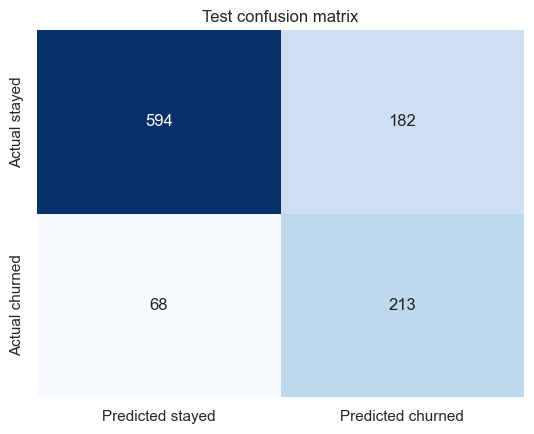

In [15]:
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

final_metrics = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_predictions),
    "Brier score": brier_score_loss(y_test, test_probabilities),
    "Precision@Top10%": y_test.iloc[np.argsort(-test_probabilities)[:max(1, int(np.ceil(0.10 * len(y_test))))]].mean(),
    "Recall@Top10%": y_test.iloc[np.argsort(-test_probabilities)[:max(1, int(np.ceil(0.10 * len(y_test))))]].sum() / max(int(y_test.sum()), 1),
}
final_metrics_df = pd.DataFrame([final_metrics])
display(final_metrics_df.style.format({k: "{:.3f}" for k in final_metrics if k != "Model"}))

print(classification_report(y_test, test_predictions, target_names=["Stayed", "Churned"], zero_division=0))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Predicted stayed", "Predicted churned"],
            yticklabels=["Actual stayed", "Actual churned"], ax=ax)
ax.set_title("Test confusion matrix")
plt.tight_layout()
plt.show()

### Uncertainty around test-set ranking metrics

A single test split gives one estimate. A bootstrap interval provides a rough view of sampling uncertainty on this test set. This does not account for dataset shift or temporal uncertainty.

In [16]:
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_ap, bootstrap_roc = [], []
y_test_array = y_test.to_numpy()
for _ in range(1000):
    sample_idx = rng.integers(0, len(y_test_array), size=len(y_test_array))
    y_boot = y_test_array[sample_idx]
    p_boot = test_probabilities[sample_idx]
    if np.unique(y_boot).size < 2:
        continue
    bootstrap_ap.append(average_precision_score(y_boot, p_boot))
    bootstrap_roc.append(roc_auc_score(y_boot, p_boot))

bootstrap_summary = pd.DataFrame([
    {"metric": "PR-AUC", "estimate": average_precision_score(y_test, test_probabilities),
     "ci_2.5%": np.quantile(bootstrap_ap, 0.025), "ci_97.5%": np.quantile(bootstrap_ap, 0.975)},
    {"metric": "ROC-AUC", "estimate": roc_auc_score(y_test, test_probabilities),
     "ci_2.5%": np.quantile(bootstrap_roc, 0.025), "ci_97.5%": np.quantile(bootstrap_roc, 0.975)},
])
display(bootstrap_summary.style.format({"estimate": "{:.3f}", "ci_2.5%": "{:.3f}", "ci_97.5%": "{:.3f}"}))

,metric,estimate,ci_2.5%,ci_97.5%
0,PR-AUC,0.659,0.601,0.717
1,ROC-AUC,0.845,0.820,0.872


### Interpretation of classification errors

- **False negative:** a customer who churned but was not flagged at the chosen threshold. In a retention workflow, this is a missed opportunity.
- **False positive:** a customer flagged as at-risk who did not churn. This can waste campaign capacity or incentive budget.

The “best” threshold depends on operational constraints and the relative cost of these two error types. The F1-selected threshold is only a statistical reference point.

## 14. Probability calibration

A ranking model can have a good PR-AUC but still produce probabilities that are systematically too high or too low. The selected estimator is calibrated with sigmoid/Platt scaling using cross-validation on the training partition only. We report the Brier score and a reliability diagram on the untouched test set. With a small dataset, bins can be noisy; inspect both the curve and bin counts.

,mean_predicted_probability,observed_churn_rate
0,0.006,0.009
1,0.020,0.028
2,0.044,0.029
3,0.086,0.113
4,0.151,0.170
5,0.226,0.238
6,0.320,0.302
7,0.450,0.381
8,0.565,0.623
9,0.702,0.764


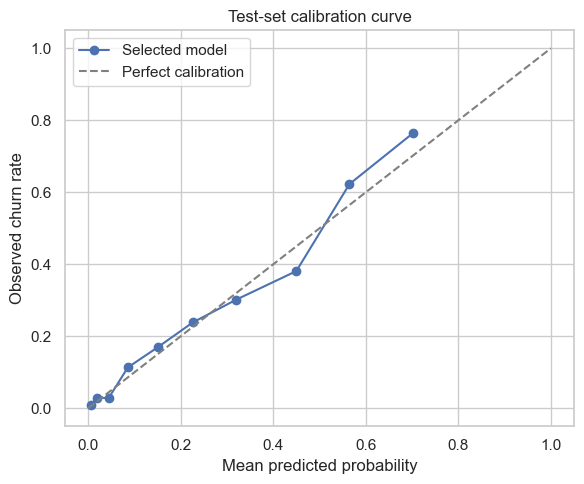

In [17]:
prob_true, prob_pred = calibration_curve(y_test, test_probabilities, n_bins=10, strategy="quantile")
calibration_bins = pd.DataFrame({"mean_predicted_probability": prob_pred,
                                 "observed_churn_rate": prob_true})
display(calibration_bins)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, marker="o", label="Selected model")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Test-set calibration curve")
ax.legend()
plt.tight_layout()
plt.show()

## 15. Model explainability: permutation importance

Permutation importance measures how much a validation score falls when one input feature is shuffled. It is calculated on the **original, untransformed validation columns**, so the results are easier to communicate to a business audience. Importance is predictive, not causal; correlated features may share or mask importance.

,feature,importance_mean,importance_std
4,tenure,0.261,0.020
7,InternetService,0.068,0.020
14,Contract,0.051,0.021
18,TotalCharges,0.032,0.017
17,MonthlyCharges,0.025,0.013
11,TechSupport,0.008,0.008
13,StreamingMovies,0.007,0.007
15,PaperlessBilling,0.007,0.012
8,OnlineSecurity,0.006,0.011
9,OnlineBackup,0.005,0.007


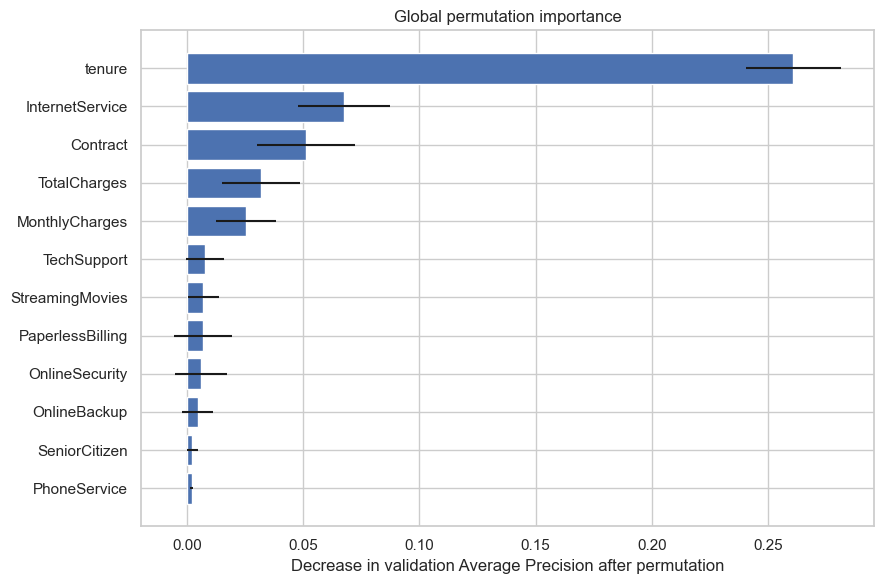

In [18]:
permutation = permutation_importance(
    calibrated_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": permutation.importances_mean,
    "importance_std": permutation.importances_std,
}).sort_values("importance_mean", ascending=False)
display(importance_df.head(15))

plot_importance = importance_df.head(12).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(plot_importance["feature"], plot_importance["importance_mean"],
         xerr=plot_importance["importance_std"])
plt.xlabel("Decrease in validation Average Precision after permutation")
plt.title("Global permutation importance")
plt.tight_layout()
plt.show()

## 16. Risk ranking & segment-level model diagnostics

For retention operations, ranking is often as important as the binary decision. The test customers are grouped into risk deciles (decile 1 = lowest predicted risk, decile 10 = highest). Compare mean predicted risk with the observed test churn rate. This is a retrospective diagnostic, not an input to campaign targeting.

,risk_decile,customers,mean_predicted_risk,observed_churn_rate
0,1,106,0.006,0.009
1,2,106,0.020,0.028
2,3,105,0.044,0.029
3,4,106,0.086,0.113
4,5,106,0.151,0.170
5,6,105,0.226,0.238
6,7,106,0.320,0.302
7,8,105,0.450,0.381
8,9,106,0.565,0.623
9,10,106,0.702,0.764


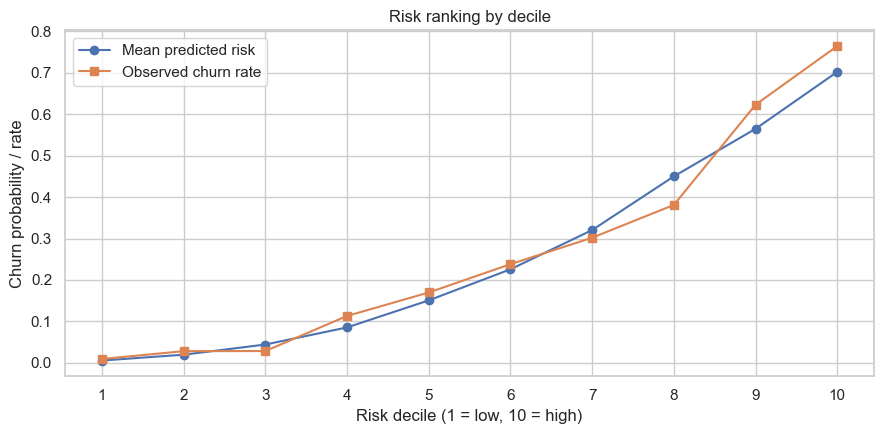

In [19]:
test_scored = pd.DataFrame({
    "customerID": customer_ids.loc[X_test.index].values,
    "churn_probability": test_probabilities,
    "actual_churn": y_test.values,
}, index=X_test.index)

test_scored["risk_decile"] = 1 + pd.qcut(
    test_scored["churn_probability"].rank(method="first"),
    q=10,
    labels=False,
    duplicates="drop",
)

decile_summary = test_scored.groupby("risk_decile", observed=True).agg(
    customers=("actual_churn", "size"),
    mean_predicted_risk=("churn_probability", "mean"),
    observed_churn_rate=("actual_churn", "mean"),
).reset_index().sort_values("risk_decile")
display(decile_summary)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(decile_summary["risk_decile"], decile_summary["mean_predicted_risk"], marker="o", label="Mean predicted risk")
ax.plot(decile_summary["risk_decile"], decile_summary["observed_churn_rate"], marker="s", label="Observed churn rate")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Risk decile (1 = low, 10 = high)")
ax.set_ylabel("Churn probability / rate")
ax.set_title("Risk ranking by decile")
ax.legend()
plt.tight_layout()
plt.show()

### Performance slices & responsible use

Check whether errors are materially different across broad groups. This is a diagnostic, not a complete fairness audit. Before deployment, define the applicable legal/policy requirements, review feature eligibility and validate on representative current data. Sensitive or protected attributes should not be used for decisions without a documented lawful basis and governance review.

In [20]:
slice_frame = X_test[["gender", "SeniorCitizen"]].copy()
slice_frame["actual"] = y_test
slice_frame["predicted"] = test_predictions
slice_rows = []

for group_col in ["gender", "SeniorCitizen"]:
    for group_value, group in slice_frame.groupby(group_col, dropna=False, observed=False):
        slice_rows.append({
            "group_feature": group_col,
            "group": str(group_value),
            "customers": len(group),
            "observed_churn_rate": group["actual"].mean(),
            "recall": recall_score(group["actual"], group["predicted"], zero_division=0),
            "false_positive_rate": (
                ((group["predicted"] == 1) & (group["actual"] == 0)).sum()
                / max((group["actual"] == 0).sum(), 1)
            ),
        })

slice_metrics = pd.DataFrame(slice_rows)
display(slice_metrics)

,group_feature,group,customers,observed_churn_rate,recall,false_positive_rate
0,gender,Female,505,0.291,0.741,0.254
1,gender,Male,552,0.243,0.776,0.218
2,SeniorCitizen,0,896,0.234,0.714,0.211
3,SeniorCitizen,1,161,0.441,0.887,0.411


**Reading the slice table.** Senior customers churn more often in the test set (44.1% versus 23.4%), and the model catches most of them (recall 0.89). Its false-positive rate for seniors, however, is about twice as high (0.41 versus 0.21). In a campaign, that means more budget spent on customers who would have stayed. This is a reason to review calibration and feature eligibility by segment before any deployment. It is a diagnostic on a single test split, not a fairness audit.

## 17. Retention campaign economics (assumption-based scenario)

The model estimates churn probability. It does **not** estimate whether a discount or call will prevent churn. To demonstrate decision support, the following section applies explicit hypothetical assumptions:

- campaign contact cost per customer;
- campaign effectiveness among customers who would otherwise churn;
- contribution margin as a share of monthly charges;
- number of months of contribution preserved if retention succeeds;
- a fixed total campaign budget.

For customer *i*:

\[
EV_i = P(Churn_i) \times Effectiveness \times MonthlyCharges_i
       \times Horizon \times Margin - ContactCost
\]

This is an illustrative expected-value proxy, **not realized profit or causal uplift**. The effectiveness parameter must be estimated from a controlled campaign experiment before business deployment.

In [21]:
# Explicit business assumptions — edit these with the hiring team / business owner.
CAMPAIGN_COST = 20.0                 # monetary units per contacted customer
CAMPAIGN_EFFECTIVENESS = 0.25       # assumed prevented-churn share among would-be churners
CONTRIBUTION_MARGIN = 0.35          # assumed contribution margin
RETENTION_HORIZON_MONTHS = 6        # assumed months of contribution preserved
CAMPAIGN_BUDGET = 2_000.0           # total available contact budget

business_scored = pd.DataFrame({
    "customerID": customer_ids.loc[X_test.index].values,
    "churn_probability": test_probabilities,
    "monthly_charges": X_test["MonthlyCharges"].to_numpy(),
}, index=X_test.index)

business_scored["contribution_if_retained"] = (
    business_scored["monthly_charges"]
    * RETENTION_HORIZON_MONTHS
    * CONTRIBUTION_MARGIN
)
business_scored["expected_value_before_contact_cost"] = (
    business_scored["churn_probability"]
    * CAMPAIGN_EFFECTIVENESS
    * business_scored["contribution_if_retained"]
)
business_scored["expected_net_value"] = (
    business_scored["expected_value_before_contact_cost"] - CAMPAIGN_COST
)

positive_value_pool = business_scored[business_scored["expected_net_value"] > 0].copy()
priority_list = positive_value_pool.sort_values("expected_net_value", ascending=False).copy()
priority_list["cumulative_contact_cost"] = CAMPAIGN_COST * np.arange(1, len(priority_list) + 1)
priority_list = priority_list[priority_list["cumulative_contact_cost"] <= CAMPAIGN_BUDGET]

summary = {
    "test_customers_scored": len(business_scored),
    "positive_expected_value_customers": len(positive_value_pool),
    "campaign_budget": CAMPAIGN_BUDGET,
    "contact_cost": CAMPAIGN_COST,
    "customers_selected": len(priority_list),
    "budget_used": len(priority_list) * CAMPAIGN_COST,
    "expected_net_value_proxy": priority_list["expected_net_value"].sum(),
}
display(pd.DataFrame([summary]))
display(priority_list.head(20))

,test_customers_scored,positive_expected_value_customers,campaign_budget,contact_cost,customers_selected,budget_used,expected_net_value_proxy
0,1057,229,"2,000.000",20.000,100,"2,000.000","1,244.081"


,customerID,churn_probability,monthly_charges,contribution_if_retained,expected_value_before_contact_cost,expected_net_value,cumulative_contact_cost
2797,6023-YEBUP,0.804,100.950,211.995,42.599,22.599,20.000
2631,6861-XWTWQ,0.810,99.250,208.425,42.198,22.198,40.000
3380,5178-LMXOP,0.840,95.100,199.710,41.950,21.950,60.000
3956,4587-VVTOX,0.752,105.300,221.130,41.547,21.547,80.000
6866,0295-PPHDO,0.821,95.450,200.445,41.117,21.117,100.000
3727,9057-SIHCH,0.807,96.600,202.860,40.918,20.918,120.000
6562,3621-CEOVK,0.753,100.200,210.420,39.616,19.616,140.000
755,6683-VLCTZ,0.751,98.550,206.955,38.835,18.835,160.000
486,9094-AZPHK,0.719,100.150,210.315,37.812,17.812,180.000
2708,8510-AWCXC,0.714,100.800,211.680,37.804,17.804,200.000


### Segment prioritization matrix

Combine predicted risk with a simple customer-value proxy (monthly charges). The quadrant labels are operational shorthand, not intrinsic customer labels. The contact list above is ranked by expected net value; the matrix below helps describe the portfolio of customers.

In [22]:
business_scored["risk_segment"] = np.where(
    business_scored["churn_probability"] >= business_scored["churn_probability"].quantile(0.75),
    "High risk", "Lower risk"
)
business_scored["value_segment"] = np.where(
    business_scored["monthly_charges"] >= business_scored["monthly_charges"].quantile(0.75),
    "Higher charges", "Lower charges"
)

priority_matrix = business_scored.groupby(["risk_segment", "value_segment"], observed=True).agg(
    customers=("customerID", "size"),
    mean_churn_risk=("churn_probability", "mean"),
    mean_monthly_charges=("monthly_charges", "mean"),
    mean_expected_net_value=("expected_net_value", "mean"),
).reset_index()
display(priority_matrix)

,risk_segment,value_segment,customers,mean_churn_risk,mean_monthly_charges,mean_expected_net_value
0,High risk,Higher charges,91,0.613,97.032,11.198
1,High risk,Lower charges,174,0.595,69.038,1.805
2,Lower risk,Higher charges,174,0.199,100.754,-9.574
3,Lower risk,Lower charges,618,0.125,46.061,-16.765


### Sensitivity analysis

The campaign recommendation is only as credible as its assumptions. Recalculate the budget-constrained list under less favourable and more favourable campaign effectiveness, margin and contact cost. If the expected net value changes sign, the decision is sensitive and should not be presented as a robust business case.

In [23]:
scenarios = [
    {"name": "Base case", "effectiveness": 0.25, "margin": 0.35, "cost": 20.0},
    {"name": "Lower effectiveness", "effectiveness": 0.15, "margin": 0.35, "cost": 20.0},
    {"name": "Higher contact cost", "effectiveness": 0.25, "margin": 0.35, "cost": 30.0},
    {"name": "Lower margin", "effectiveness": 0.25, "margin": 0.25, "cost": 20.0},
]

sensitivity_rows = []
for scenario in scenarios:
    ev = (
        business_scored["churn_probability"]
        * scenario["effectiveness"]
        * business_scored["monthly_charges"]
        * RETENTION_HORIZON_MONTHS
        * scenario["margin"]
        - scenario["cost"]
    )
    selected = ev[ev > 0].sort_values(ascending=False)
    max_contacts = int(CAMPAIGN_BUDGET // scenario["cost"])
    selected = selected.head(max_contacts)
    sensitivity_rows.append({
        "scenario": scenario["name"],
        "effectiveness": scenario["effectiveness"],
        "margin": scenario["margin"],
        "contact_cost": scenario["cost"],
        "customers_selected": len(selected),
        "budget_used": len(selected) * scenario["cost"],
        "expected_net_value_proxy": selected.sum(),
        "campaign_positive_value": bool(selected.sum() > 0),
    })

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results)

,scenario,effectiveness,margin,contact_cost,customers_selected,budget_used,expected_net_value_proxy,campaign_positive_value
0,Base case,0.250,0.350,20.000,100,"2,000.000","1,244.081",True
1,Lower effectiveness,0.150,0.350,20.000,37,740.000,77.326,True
2,Higher contact cost,0.250,0.350,30.000,66,"1,980.000",293.623,True
3,Lower margin,0.250,0.250,20.000,90,"1,800.000",319.765,True


## 18. What about Next Best Offer (NBO)?

This project supports **churn-risk ranking and retention-contact prioritization**, but it does not train an NBO model. The available fields describe customers and services; there are no rows representing offers shown, treatment assignment, offer acceptance, incremental revenue or post-offer outcomes.

A defensible NBO / uplift extension would require at least:

- customer × offer exposure history with timestamps;
- eligibility and treatment/control assignment;
- acceptance, redemption and post-offer churn outcomes;
- offer cost, margin and channel constraints;
- repeated observations to evaluate incremental impact.

With that data, the next iteration could estimate treatment effects or uplift by offer, then optimize the offer under budget and eligibility constraints. Choosing the offer with the highest predicted acceptance is not equivalent to choosing the offer with the highest incremental business value.

## 19. Model limitations, deployment considerations & next steps

### Current limitations

1. **No time dimension:** random splitting estimates interpolation within this sample; it does not establish forward-looking performance. Use a time-based split once timestamped snapshots exist.
2. **No campaign outcomes:** retention effectiveness is a scenario assumption, not learned from the data.
3. **Small public sample:** 7k rows is useful for a portfolio case, not a credible demonstration of large-scale data engineering.
4. **Potential drift:** products, pricing, payment behaviour and customer mix can change; monitor prevalence, calibration and feature distributions.
5. **Observational features:** permutation importance and segment rates describe association, not causation.
6. **Governance:** audit group-level errors, remove features that are not legally or ethically eligible, and keep a human/business approval step for outreach.

### Production-oriented next steps

- define a feature snapshot date and 30/60/90-day label horizon;
- build point-in-time correct SQL feature tables and temporal validation;
- track model version, training data window, feature schema and evaluation metrics;
- expose batch scoring through a scheduled job or a REST API;
- persist scores with `customer_id`, `scored_at`, `model_version`, probability and reason codes;
- monitor data quality, drift, precision@K, recall@K, calibration and campaign outcomes;
- run randomized retention experiments to estimate uplift and validate campaign effectiveness;
- build NBO only after offer exposure and outcome data are available.

## 20. Export model & decision-support artifacts

The final section exports a reusable model bundle, a customer-level test score file and a budget-constrained target list. The target list intentionally excludes the ground-truth churn label. Review local data-protection rules before exporting or sharing customer-level data; this public sample is anonymized, but the same workflow may be applied to sensitive production records.

In [24]:
EXPORT_ARTIFACTS = True
ARTIFACT_DIR = Path("artifacts")

if EXPORT_ARTIFACTS:
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

    try:
        import joblib
        model_bundle = {
            "model": calibrated_model,
            "model_name": best_model_name,
            "threshold": best_threshold,
            "feature_columns": X_train.columns.tolist(),
            "numeric_features": numeric_features,
            "categorical_features": categorical_features,
            "random_state": RANDOM_STATE,
            "trained_at_utc": datetime.now(timezone.utc).isoformat(),
        }
        joblib.dump(model_bundle, ARTIFACT_DIR / "churn_model_bundle.joblib")
    except Exception as export_error:
        warnings.warn(f"Model export skipped: {export_error}")

    test_scored.to_csv(ARTIFACT_DIR / "test_customer_scores.csv", index=False)
    priority_list[[
        "customerID", "churn_probability", "monthly_charges",
        "expected_net_value", "cumulative_contact_cost"
    ]].to_csv(ARTIFACT_DIR / "retention_priority_list.csv", index=False)

    metadata = {
        "project": "Customer Retention Intelligence",
        "dataset_source": DATA_SOURCE,
        "model_name": best_model_name,
        "threshold": best_threshold,
        "test_metrics": {k: (float(v) if isinstance(v, (np.floating, float, int, np.integer)) else v)
                         for k, v in final_metrics.items()},
        "campaign_assumptions": {
            "campaign_cost": CAMPAIGN_COST,
            "campaign_effectiveness": CAMPAIGN_EFFECTIVENESS,
            "contribution_margin": CONTRIBUTION_MARGIN,
            "retention_horizon_months": RETENTION_HORIZON_MONTHS,
            "campaign_budget": CAMPAIGN_BUDGET,
        },
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    with open(ARTIFACT_DIR / "model_card_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)

    print(f"Artifacts saved to: ./{ARTIFACT_DIR}/")
else:
    print("Artifact export is disabled. Set EXPORT_ARTIFACTS = True to save files.")

Artifacts saved to: ./artifacts/


## 21. Executive summary

**Problem.** A retention team with a fixed contact budget needs to decide which customers to call first.

**Data.** 7,043 telecom customers from the IBM Telco sample, of whom 26.5% churned. Quality checks found no duplicate IDs and no unmapped labels. The 11 blank `TotalCharges` values are imputed inside the training pipeline.

**Model.** Logistic Regression had the highest validation PR-AUC (0.631, against 0.619 for Random Forest and 0.607 for the scratch Naive Bayes). On the untouched test set it reaches PR-AUC 0.659 (95% bootstrap interval 0.601–0.717) and ROC-AUC 0.845, against 0.265 for the prior baseline. At the validation-tuned threshold of 0.29, precision is 0.54, recall 0.76 and F1 0.63. The top 10% of customers by predicted risk contain 76% churners and capture 29% of all churners.

**Drivers.** The three strongest permutation-importance features are tenure, internet service type and contract type. These describe association, not cause.

**Action.** Under assumed campaign economics ($20 per contact, 25% effectiveness, 35% margin, six months of retained contribution and a $2,000 budget), the model selects 100 of 1,057 test customers, with an expected net value proxy of about 1,244. This depends on the assumptions. If effectiveness falls to 15%, the list shrinks to 37 contacts and the value to about 77. The result stays positive in all four sensitivity scenarios, but effectiveness must be measured in a controlled experiment before it is used for decisions.

**Caveats.** The split is random, so there is no temporal validation. The data has no campaign or offer history, the sample is small and public, and no Next Best Offer model was trained.

### 30-second pitch

“I built a churn classification and retention-prioritisation workflow on the IBM Telco sample. I prevented preprocessing leakage with train-only pipelines, compared a from-scratch categorical Naive Bayes with Logistic Regression and Random Forest, selected the model by validation PR-AUC and tuned the threshold on validation data. The final test PR-AUC is 0.66 against a 0.27 baseline. I then turned risk scores into a budget-limited contact list using explicit assumptions and a sensitivity analysis. I did not claim causal uplift, because the dataset has no treatment or offer-response history.”

---

### Reproducibility checklist

- [ ] Install packages with `pip install -r requirements.txt`.
- [ ] Download the CSV or let the notebook use the public IBM mirror.
- [ ] Run all cells from top to bottom (the scratch Naive Bayes is defined in this notebook; no extra modules are needed).
- [ ] Inspect the test metrics, calibration and risk-decile tables.
- [ ] Replace the illustrative campaign assumptions with business-approved estimates.
- [ ] Commit the notebook, `README.md` and `requirements.txt`. Add `artifacts/` to `.gitignore`, since it contains customer-level scores.